# Access IPERLITE data using openEO

The IPERLITE Hyperspectral In-Orbit Demonstration Mission is a Belgian-led Earth-observation satellite mission that launched on November 28, 2025, via a SpaceX Falcon 9 rocket from the Vandenberg Space Force Base in California.

The IPERLITE mission, led by VITO, represents a new generation of compact hyperspectral satellites designed to deliver high-quality Earth observation data from a smaller platform.

The data collected and processed by the IPERLITE mission is made available through the Terrascope STAC catalogue, enabling researchers and practitioners to access high-quality hyperspectral imagery for a range of Earth observation applications.

This notebook explores the IPERLITE collections available through the Terrascope STAC catalogue, selects a product, and uses openEO to load data for a region of interest. The notebook does not cover advanced data analysis or processing; it focuses on easy access to IPERLITE data via the openEO API.

In [1]:
from pystac_client import Client
import pandas as pd

First, connect to the Terrascope STAC catalogue and inspect its available collections. The catalogue metadata gives a quick overview of the products and their temporal coverage.

In [2]:
stac_url = "https://stac.terrascope.be/"
client = Client.open(stac_url)
collections = list(client.get_collections())
print(f"Total collections available in the Terrascope STAC catalogue: {len(collections)}")

Total collections available in the Terrascope STAC catalogue: 108


In [3]:
# get the collection whose id has with "iperlite" in it
iperlite_collections = [c for c in collections if "iperlite" in c.id]
print(f"Found {len(iperlite_collections)} collections that have 'iperlite' in their id")
for c in iperlite_collections:
    print(c.id)


Found 2 collections that have 'iperlite' in their id
terrascope-iperlite-l1c-cog-v1
terrascope-iperlite-l2a-cog-v1


As shown above, two collections: terrascope-iperlite-l1c-cog-v1 and terrascope-iperlite-l2a-cog-v1 are available in the Terrascope STAC catalogue for the IPERLITE mission as of October 2026. Further details about these collections, including their metadata, can be explored directly through the STAC catalogue.

In [4]:
collection_overview = []

for collection in iperlite_collections:
    temporal_intervals = collection.extent.temporal.intervals
    collection_overview.append(
        {
            "Collection ID": collection.id,
            "Title": collection.title,
            "Temporal extent": temporal_intervals[0] if temporal_intervals else None,
            "Description": collection.description,
        }
    )

overview_df = pd.DataFrame(collection_overview)
display(
    overview_df.style.set_properties(
        subset=["Description"],
        **{"white-space": "normal", "max-width": "500px"},
    )
)

,Collection ID,Title,Temporal extent,Description
0,terrascope-iperlite-l1c-cog-v1,"IPERLITE L1C top of atmosphere (TOA) reflectance hyperspectral products, COG format - Version 1","[datetime.datetime(2026, 6, 1, 0, 0, tzinfo=tzutc()), None]","IPERLITE Level-1C products are top of atmosphere (TOA) reflectance hyperspectral products from the IPERLITE in‑orbit demonstration mission, intended to support downstream processing and experimentation (e.g., STAC/openEO integration). Data are collected by the CSIMBA instrument and provide hyperspectral observations at 20 m ground sampling distance with 133 bands spanning 450–900 nm."
1,terrascope-iperlite-l2a-cog-v1,"IPERLITE L2A top of canopy (TOC) reflectance hyperspectral products, COG format - Version 1","[datetime.datetime(2026, 6, 1, 0, 0, tzinfo=tzutc()), None]","IPERLITE Level-2A products are top of canopy (TOC) reflectance hyperspectral products from the IPERLITE in‑orbit demonstration mission, intended to support downstream processing and experimentation (e.g., STAC/openEO integration). Data are collected by the CSIMBA instrument and provide hyperspectral observations at 20 m ground sampling distance with 133 bands spanning 450–900 nm."


The table summarizes the IPERLITE products returned by the catalogue. For this example, we will use the Level 2A collection, which provides top-of-canopy reflectance.

In [5]:
collection_id = "terrascope-iperlite-l2a-cog-v1"
# stac_url = f"https://stac.terrascope.be/collections/{collection_id}"
dev_stac_url = f"https://stac-api-dev.vgt.vito.be/collections/{collection_id}"
print(dev_stac_url)

https://stac-api-dev.vgt.vito.be/collections/terrascope-iperlite-l2a-cog-v1


Now, let us use the openEO API to access and work with the IPERLITE data available in the Terrascope STAC catalogue. While the cell below simply downloads the data for a specific region of interest, the openEO API allows for more advanced processing and analysis workflows on the cloud.

In [6]:
import openeo
connection = openeo.connect("openeo.terrascope.be").authenticate_oidc()

Authenticated using refresh token.


The AOI is a GeoJSON polygon around a region in northern Italy.

In [ ]:
aoi = {
  "type": "FeatureCollection",
  "features": [
    {
      "type": "Feature",
      "properties": {},
      "geometry": {
        "type": "Polygon",
        "coordinates": [
          [
            [
              12.2176821,
              45.3390293
            ],
            [
              12.2176821,
              45.3874859
            ],
            [
              12.0598993,
              45.3874859
            ],
            [
              12.0598993,
              45.3390293
            ],
            [
              12.2176821,
              45.3390293
            ]
          ]
        ]
      }
    }
  ]
}
# download the data for a region in Italy
cube = connection.load_stac(
    url = stac_url,
    # spatial_extent = {"west": 12.0, "south": 45.2, "east": 12.3, "north": 45.4}
    spatial_extent = aoi
    )
cube.execute_batch(title="simple download using openEO", outputfile="iperlite_italy.nc")



0:00:00 Job 'j-261013074858441aa9efcbe122041e9d': send 'start'
0:00:17 Job 'j-261013074858441aa9efcbe122041e9d': created (progress 0%)
0:00:22 Job 'j-261013074858441aa9efcbe122041e9d': queued (progress 0%)
0:00:29 Job 'j-261013074858441aa9efcbe122041e9d': queued (progress 0%)
0:00:37 Job 'j-261013074858441aa9efcbe122041e9d': queued (progress 0%)
0:00:47 Job 'j-261013074858441aa9efcbe122041e9d': queued (progress 0%)
0:00:59 Job 'j-261013074858441aa9efcbe122041e9d': queued (progress 0%)
0:01:15 Job 'j-261013074858441aa9efcbe122041e9d': queued (progress 0%)
0:01:34 Job 'j-261013074858441aa9efcbe122041e9d': queued (progress 0%)
0:01:58 Job 'j-261013074858441aa9efcbe122041e9d': running (progress 14.9%)
0:02:28 Job 'j-261013074858441aa9efcbe122041e9d': running (progress 18.4%)
0:03:06 Job 'j-261013074858441aa9efcbe122041e9d': running (progress 22.3%)
0:03:53 Job 'j-261013074858441aa9efcbe122041e9d': running (progress 26.8%)
0:04:52 Job 'j-261013074858441aa9efcbe122041e9d': running (progress 

<BatchJob job_id='j-261013074858441aa9efcbe122041e9d'>

In [10]:
# visualise the result

import xarray as xr

ds = xr.open_dataset("iperlite_italy.nc")
ds

<xarray.Dataset> Size: 527MB
Dimensions:   (t: 1, y: 272, x: 884)
Coordinates:
  * t         (t) datetime64[ns] 8B 2026-08-26
  * y         (y) float64 2kB 45.39 45.39 45.39 45.39 ... 45.34 45.34 45.34
  * x         (x) float64 7kB 12.06 12.06 12.06 12.06 ... 12.22 12.22 12.22
Data variables: (12/275)
    crs       |S1 1B ...
    RTOC#1    (t, y, x) float64 2MB ...
    RTOC#2    (t, y, x) float64 2MB ...
    RTOC#3    (t, y, x) float64 2MB ...
    RTOC#4    (t, y, x) float64 2MB ...
    RTOC#5    (t, y, x) float64 2MB ...
    ...        ...
    RTOC94    (t, y, x) float64 2MB ...
    RTOC95    (t, y, x) float64 2MB ...
    RTOC96    (t, y, x) float64 2MB ...
    RTOC97    (t, y, x) float64 2MB ...
    RTOC98    (t, y, x) float64 2MB ...
    RTOC99    (t, y, x) float64 2MB ...
Attributes:
    Conventions:  CF-1.9
    institution:  VITO Terrascope openEO API - 0.73.0a20.dev20260926+133
    description:  
    title:

After the batch job completes, open the downloaded NetCDF file with xarray to inspect its dimensions, coordinates, and available reflectance bands.

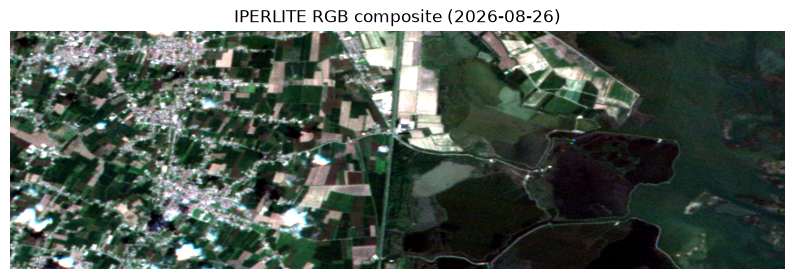

In [11]:
import numpy as np
import matplotlib.pyplot as plt

red = ds["RTOC52"].isel(t=0).values
green = ds["RTOC23"].isel(t=0).values
blue = ds["RTOC6"].isel(t=0).values

rgb = np.stack([red, green, blue], axis=-1)
lower, upper = np.nanpercentile(rgb, (2, 98), axis=(0, 1))
rgb = np.clip((rgb - lower) / (upper - lower), 0, 1)

plt.figure(figsize=(10, 6))
plt.imshow(rgb)
plt.title(f"IPERLITE RGB composite ({str(ds.t.values[0])[:10]})")
plt.axis("off")
plt.show()

For a simple natural-colour view, combine bands RTOC52, RTOC23, and RTOC6 as red, green, and blue. The percentile stretch improves contrast for display; it changes only the visualization, not the reflectance values in the downloaded data.

This example demonstrates the workflow from STAC discovery through openEO loading to local visualization. You can adapt the collection, AOI, or selected bands for another IPERLITE use case.